# Система автоматического улучшения качества фотографий
**Яркость · контраст · резкость · шум · колоризация чёрно-белых снимков**
Курс «Компьютерное зрение 1», итоговый проект. Платформа: Google Colab.

## 1. Постановка задачи
**Задача.** Автоматически (без ручной настройки параметров) улучшить фотографию: исправить яркость, контраст, резкость, снизить шум, а для чёрно-белых снимков восстановить цвет.

**Вход:** фото (цветное или чёрно-белое) произвольного качества. **Выход:** улучшенное фото + отчёт (какие проблемы найдены, что сделано, как изменились метрики).

**Почему это нужно.** Старые сканы, снимки при плохом освещении и фото с телефона в сумерках — типичные кейсы; ручная правка каждого снимка в редакторе неудобна, а фиксированные параметры («везде CLAHE 2.0») на одних фото помогают, на других портят.

**Ключевая идея проекта: сначала диагностика, потом лечение.** Конвейер измеряет качество снимка (яркость, динамический диапазон, шум, размытость) и применяет **только нужные шаги с параметрами, подобранными под снимок**. Хорошее фото остаётся нетронутым («не навреди»).

## 2. Выбор методов и их ограничения
| Проблема | Метод | Почему именно он | Ограничения |
|---|---|---|---|
| Шум | Non-Local Means (`fastNlMeans`), сила `h` по оценке σ шума | Сохраняет текстуры лучше, чем гауссов/медианный фильтр; сила подбирается под σ | Медленнее простых фильтров; при сильном шуме «пластилинит» детали |
| Яркость | Адаптивная гамма-коррекция (LUT) в канале L | Нелинейно осветляет тени, почти не трогает светлые; быстро (таблица из 256 значений) | Глобальная: не знает замысла снимка (ночная сцена будет осветлена) |
| Контраст | Растяжение гистограммы по перцентилям 1–99 % + мягкий CLAHE | Растяжение устойчиво к выбросам; CLAHE добавляет локальный контраст там, где глобально не вытянуть | CLAHE усиливает шум (поэтому шум убираем первым); растяжение не восстанавливает засветку |
| Резкость | Нерезкая маска (unsharp) + маска контуров (Canny + морфология) | Усиливает детали, а маска контуров не даёт усиливать шум на плоских областях | Не возвращает потерянные детали (только усиливает оставшиеся); возможны «ореолы» |
| Цвет ч/б | Предобученная CNN (Zhang et al., 2016) + классическая постобработка | Цвет по яркости не восстановить классикой — задача неоднозначна, нужны «знания о мире» | Цвета правдоподобные, а не истинные; цветовые пятна и «протекание» через границы |
| Цветовое пространство | LAB: меняем только L, каналы a/b не трогаем | Яркость и цвет разделены → улучшение не сдвигает оттенки (в RGB они бы «поплыли») | — |

**Почему классические методы, а не нейросеть для всего.** Улучшение яркости, контраста и резкости — задача, где классика даёт предсказуемый, объяснимый и быстрый результат (десятки миллисекунд на CPU), не требует данных и не «выдумывает» детали. Нейросеть здесь используется только там, где классика принципиально бессильна, — для колоризации.

In [1]:
import os, time, urllib.request, warnings
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skimage.data as sd          # только для учебных тестовых снимков

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 90
os.makedirs('results', exist_ok=True)

def save_fig(name):
    plt.savefig(f'results/{name}.png', dpi=110, bbox_inches='tight')

def show(images, titles=None, cols=None, size=4.5, name=None):
    """Показывает список изображений (BGR или gray) в сетке."""
    cols = cols or len(images); rows = int(np.ceil(len(images) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 0.85)); axs = np.array(axs).reshape(-1)
    for ax in axs: ax.axis('off')
    for i, im in enumerate(images):
        axs[i].imshow(im if im.ndim == 2 else cv2.cvtColor(im, cv2.COLOR_BGR2RGB), cmap='gray', vmin=0, vmax=255)
        if titles: axs[i].set_title(titles[i], fontsize=10)
    plt.tight_layout()
    if name: save_fig(name)
    plt.show()

## 3. Данные
* **Основной снимок** — ваша фотография (в проекте: старый чёрно-белый портрет `tesla.jpg`). Если файла нет, Colab предложит его загрузить.
* **Тестовый набор для количественной оценки** — три эталонных цветных снимка (`astronaut`, `coffee`, `chelsea` из `scikit-image`), к которым мы **искусственно добавляем дефекты** (тёмное, засвеченное, низкий контраст, размытое, шум, комбинация). Так известен «идеал», и можно честно посчитать PSNR/SSIM до и после обработки.
* **Нестандартный случай** — снимок `rocket` (ночная сцена, тёмная по замыслу): проверяем, где автоматика ошибается.

Файл: tesla.jpg | размер: (700, 537, 3) | чёрно-белое: True


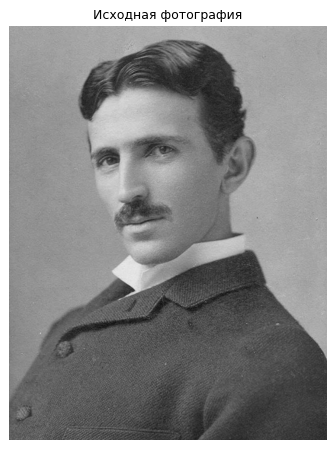

In [2]:
def limit_size(img, max_side=1200):
    h, w = img.shape[:2]; k = max_side / max(h, w)
    return img if k >= 1 else cv2.resize(img, None, fx=k, fy=k, interpolation=cv2.INTER_AREA)

def is_grayscale(img, tol=4):
    """Чёрно-белое фото, сохранённое как 3 канала: каналы почти равны."""
    if img.ndim == 2: return True
    b, g, r = [img[:, :, i].astype(np.int16) for i in range(3)]
    return max(np.abs(b - g).mean(), np.abs(g - r).mean()) < tol

def load_user_image(path='tesla.jpg'):
    if not os.path.exists(path):
        try:
            from google.colab import files
            path = list(files.upload().keys())[0]
        except Exception:
            print('Файл не найден и загрузка недоступна — берём учебный снимок skimage.data.camera()')
            return cv2.cvtColor(sd.camera(), cv2.COLOR_GRAY2BGR), 'camera'
    img = cv2.imread(path); assert img is not None, f'не удалось прочитать {path}'
    return limit_size(img), path

img, img_name = load_user_image()
print('Файл:', img_name, '| размер:', img.shape, '| чёрно-белое:', is_grayscale(img))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
show([img], ['Исходная фотография'], size=6)

## 4. Измерение качества и диагностика
Улучшать «вслепую» нельзя, поэтому сначала измеряем снимок. Все показатели считаются по каналу яркости L:

* **яркость** — среднее L; **контраст** — σ(L); **динамический диапазон** — разность 99-го и 1-го перцентилей (устойчива к единичным выбросам, в отличие от max − min);
* **доля тёмных/светлых пикселей** (L < 30 / L > 225);
* **шум σ** — оценка по методу Иммеркера (свёртка с маской-лапласианом, не реагирует на плавные градиенты);
* **резкость** — дисперсия лапласиана. Но она *растёт и от шума*, поэтому для решения «размыто ли фото» используем **коэффициент повторного размытия**: у размытого снимка дополнительное размытие почти ничего не меняет (отношение ≈ 0.6–0.7), у резкого — сильно (≈ 0.05–0.12);
* **энтропия** гистограммы (богатство тонов).

Для сравнения «до/после» с эталоном — **PSNR** и **SSIM** (структурное сходство, реализован по формуле Wang et al., 2004).

In [3]:
# ---------- метрики качества ----------
def to_L(bgr):
    """Канал яркости L (uint8, 0..255) из BGR или gray."""
    if bgr.ndim == 2: return bgr.copy()
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)[:, :, 0]

def estimate_noise(gray):
    """Оценка σ шума по Иммеркеру (Immerkaer, 1996): свёртка с лапласианом-маской,
    не реагирует на плавные градиенты и почти не реагирует на контуры."""
    g = gray.astype(np.float32)
    K = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)
    h, w = g.shape
    s = np.abs(cv2.filter2D(g, -1, K)[1:-1, 1:-1]).sum()
    return float(np.sqrt(np.pi / 2) * s / (6.0 * (w - 2) * (h - 2)))

def image_stats(img):
    L = to_L(img)
    p1, p99 = np.percentile(L, [1, 99])
    hist = np.bincount(L.ravel(), minlength=256) / L.size
    nz = hist[hist > 0]
    den = cv2.medianBlur(L, 3)                       # sharpness считаем на слегка очищенном: шум не должен «улучшать» резкость
    return {
        'яркость': float(L.mean()),
        'контраст (σ)': float(L.std()),
        'дин. диапазон (p1–p99)': float(p99 - p1),
        'тёмные, %': float((L < 30).mean() * 100),
        'светлые, %': float((L > 225).mean() * 100),
        'резкость (Var Lap)': float(cv2.Laplacian(den, cv2.CV_64F).var()),
        'шум σ': estimate_noise(L),
        'энтропия': float(-(nz * np.log2(nz)).sum()),
    }

def psnr(a, b):
    return float(cv2.PSNR(a, b))

def ssim(a, b):
    """SSIM (Wang et al., 2004), гауссово окно 11×11, σ=1.5, по яркости."""
    a = to_L(a).astype(np.float64); b = to_L(b).astype(np.float64)
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    f = lambda x: cv2.GaussianBlur(x, (11, 11), 1.5)
    mu_a, mu_b = f(a), f(b)
    s_aa = f(a * a) - mu_a ** 2; s_bb = f(b * b) - mu_b ** 2; s_ab = f(a * b) - mu_a * mu_b
    m = ((2 * mu_a * mu_b + C1) * (2 * s_ab + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (s_aa + s_bb + C2))
    return float(m[5:-5, 5:-5].mean())

In [4]:
# ---------- диагностика ----------
def blur_ratio(L, s=1.2):
    """Показатель размытости без эталона («повторное размытие», Crete 2007): если картинку уже размыли,
    дополнительное размытие почти ничего не меняет -> отношение близко к 1; у резкой оно мало (≈0.05–0.12)."""
    Ld = cv2.medianBlur(L, 3)
    v0 = cv2.Laplacian(Ld, cv2.CV_64F).var() + 1e-9
    v1 = cv2.Laplacian(cv2.GaussianBlur(Ld, (0, 0), s), cv2.CV_64F).var()
    return float(v1 / v0)

DEFAULT_THR = dict(noise=4.5, dark=85, bright=160, dyn_range=180, blur_ratio=0.30)

def diagnose(img, thr=DEFAULT_THR):
    st = image_stats(img); L = to_L(img)
    st['blur ratio'] = blur_ratio(L)
    issues = {
        'шум':          st['шум σ'] > thr['noise'],
        'тёмное':       st['яркость'] < thr['dark'],
        'засвеченное':  st['яркость'] > thr['bright'],
        'низкий контраст': st['дин. диапазон (p1–p99)'] < thr['dyn_range'],
        'размытое':     st['blur ratio'] > thr['blur_ratio'],
    }
    return st, issues

In [5]:
stats, issues = diagnose(img)
print('Диагностика исходного снимка:')
display(pd.DataFrame({'значение': {k: round(v, 2) for k, v in stats.items()}}))
print('Обнаруженные проблемы:', [k for k, v in issues.items() if v] or 'не обнаружены')

Диагностика исходного снимка:


,значение
яркость,130.55
контраст (σ),45.38
дин. диапазон (p1–p99),170.00
"тёмные, %",0.17
"светлые, %",0.36
резкость (Var Lap),75.56
шум σ,1.93
энтропия,7.07
blur ratio,0.08


Обнаруженные проблемы: ['низкий контраст']


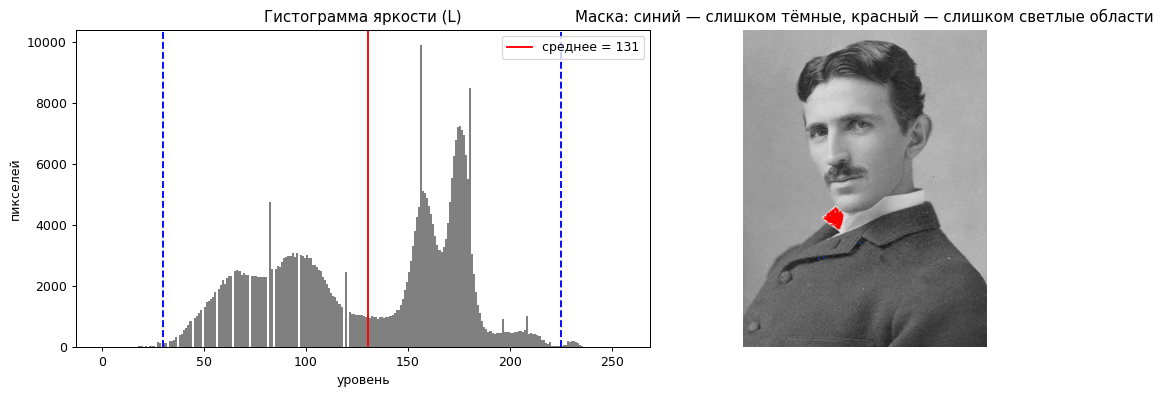

In [6]:
# Визуализация диагностики: гистограмма и маски слишком тёмных / светлых областей
# (пороговая бинаризация + морфологическое открытие, чтобы убрать одиночные пиксели)
L = to_L(img)
k = np.ones((3, 3), np.uint8)
dark_mask   = cv2.morphologyEx((L < 30).astype(np.uint8)  * 255, cv2.MORPH_OPEN, k)
bright_mask = cv2.morphologyEx((L > 225).astype(np.uint8) * 255, cv2.MORPH_OPEN, k)
overlay = cv2.cvtColor(L, cv2.COLOR_GRAY2BGR); overlay[dark_mask > 0] = (255, 80, 0); overlay[bright_mask > 0] = (0, 0, 255)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(L.ravel(), bins=256, range=(0, 256), color='gray')
ax[0].axvline(L.mean(), color='r', label=f'среднее = {L.mean():.0f}'); ax[0].axvline(30, ls='--', c='b'); ax[0].axvline(225, ls='--', c='b')
ax[0].set_title('Гистограмма яркости (L)'); ax[0].set_xlabel('уровень'); ax[0].set_ylabel('пикселей'); ax[0].legend()
ax[1].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)); ax[1].axis('off')
ax[1].set_title('Маска: синий — слишком тёмные, красный — слишком светлые области')
plt.tight_layout(); save_fig('diagnosis'); plt.show()

## 5. Конвейер улучшения
**Порядок шагов выбран не случайно:** шумоподавление → яркость → контраст → резкость. Контраст и резкость усиливают шум, поэтому шум убираем первым. Каждый шаг включается только по результату диагностики, а параметры выводятся из измеренных величин:

* сила шумоподавления `h ≈ 0.9·σ`;
* гамма подбирается так, чтобы средняя яркость сдвинулась к 120 (не полностью, а на 80 % — чтобы не «убивать» ночные сцены);
* «низкий контраст» диагностируется, если динамический диапазон (p1–p99) меньше 180 из 255; растяжение ограничено коэффициентом 2.5; CLAHE подключается только если контраст после растяжения всё ещё мал;
* сила нерезкой маски растёт с размытостью; маска контуров (Canny → дилатация → размытие) применяется, если был шум.

Для сравнения реализован **исходный конвейер проекта** (`baseline_enhance`): median → CLAHE(2.0) → unsharp 1.5/−0.5 с фиксированными параметрами.

In [7]:
# ---------- шаги улучшения ----------
def adaptive_gamma(L, target=120, strength=0.8, g_min=0.45, g_max=2.2):
    """Гамма-коррекция по LUT: подбираем γ так, чтобы средняя яркость пошла к target (не целиком — strength<1,
    чтобы не «убить» ночные сцены, которые тёмные по замыслу)."""
    mean = float(L.mean())
    goal = mean + strength * (target - mean)
    gamma = float(np.clip(np.log(goal / 255) / np.log(max(mean, 1) / 255), g_min, g_max))
    lut = (255 * (np.arange(256) / 255.0) ** gamma).astype(np.uint8)
    return cv2.LUT(L, lut), gamma

def stretch_contrast(L, lo_p=1, hi_p=99, out_lo=5, out_hi=250, max_gain=2.5):
    """Линейное растяжение гистограммы по перцентилям (устойчиво к выбросам); коэффициент ограничен max_gain."""
    p_lo, p_hi = np.percentile(L, [lo_p, hi_p])
    gain = min((out_hi - out_lo) / max(p_hi - p_lo, 1), max_gain)
    mid_in, mid_out = (p_lo + p_hi) / 2, (out_lo + out_hi) / 2
    return np.clip((L.astype(np.float32) - mid_in) * gain + mid_out, 0, 255).astype(np.uint8), gain

def local_contrast(L, clip=2.0, tile=8):
    return cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(L)

def edge_mask(L, feather=5):
    """Маска контуров: Canny (порог по медиане) -> дилатация (морфология) -> размытие (плавный переход)."""
    b = cv2.GaussianBlur(L, (5, 5), 0)
    med = float(np.median(b))
    lo, hi = int(max(0, 0.66 * med)), int(min(255, 1.33 * med + 20))
    e = cv2.dilate(cv2.Canny(b, lo, hi), np.ones((3, 3), np.uint8), iterations=2)
    m = cv2.GaussianBlur(e.astype(np.float32) / 255.0, (feather * 2 + 1,) * 2, 0)
    return np.clip(m * 1.5, 0, 1)

def masked_unsharp(L, amount, sigma=2.5, use_mask=True):
    """Нерезкая маска: L + amount·(L − GaussianBlur(L)); применяется только у контуров (не усиливает шум на плоских областях)."""
    Lf = L.astype(np.float32)
    detail = Lf - cv2.GaussianBlur(Lf, (0, 0), sigma)
    m = edge_mask(L) if use_mask else 1.0
    return np.clip(Lf + amount * detail * m, 0, 255).astype(np.uint8)

def denoise(img, sigma, strength=0.9):
    h = float(np.clip(strength * sigma, 2, 14))
    if img.ndim == 2: return cv2.fastNlMeansDenoising(img, None, h, 7, 21)
    return cv2.fastNlMeansDenoisingColored(img, None, h, h, 7, 21)

def _merge_L(lab, L):
    return cv2.cvtColor(cv2.merge([L, lab[:, :, 1], lab[:, :, 2]]), cv2.COLOR_LAB2BGR)

def auto_enhance(img, thr=DEFAULT_THR, return_steps=False):
    """Адаптивный конвейер. Сначала диагностика, затем ТОЛЬКО нужные шаги (принцип «не навреди»).
    Порядок: шумоподавление -> яркость -> контраст -> резкость (контраст и резкость усиливают шум, поэтому он первым)."""
    st, issues = diagnose(img, thr)
    steps, log = {'0 исходное': img.copy()}, {'проблемы': [k for k, v in issues.items() if v] or ['не обнаружены']}
    cur = img
    if issues['шум']:
        cur = denoise(img, st['шум σ']); log['denoise h'] = round(min(max(0.9 * st['шум σ'], 2), 14), 1)
    steps['1 шумоподавление'] = cur
    color = cur.ndim == 3
    lab = cv2.cvtColor(cur, cv2.COLOR_BGR2LAB) if color else None
    L = lab[:, :, 0] if color else cur.copy()
    wrap = (lambda x: _merge_L(lab, x)) if color else (lambda x: x)
    if issues['тёмное'] or issues['засвеченное']:
        L, g = adaptive_gamma(L); log['gamma'] = round(g, 2)
    steps['2 яркость'] = wrap(L)
    if issues['низкий контраст']:
        L, gain = stretch_contrast(L); log['stretch gain'] = round(gain, 2)
        if L.std() < 45: L = local_contrast(L, 1.5); log['CLAHE'] = 1.5
    steps['3 контраст'] = wrap(L)
    if issues['размытое']:
        amount = float(np.clip(2.5 * st['blur ratio'], 0.8, 2.0)); L = masked_unsharp(L, amount, use_mask=bool(issues['шум'])); log['sharp amount'] = round(amount, 2)
    out = wrap(L); steps['4 резкость'] = out
    return (out, steps, log) if return_steps else out

def baseline_enhance(img):
    """Исходный конвейер из проекта: medianBlur(3) -> CLAHE(2.0) -> unsharp 1.5/-0.5, параметры фиксированные."""
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB) if img.ndim == 3 else None
    L = lab[:, :, 0] if lab is not None else img
    L = cv2.medianBlur(L, 3)
    L = cv2.createCLAHE(2.0, (8, 8)).apply(L)
    L = cv2.addWeighted(L, 1.5, cv2.GaussianBlur(L, (5, 5), 0), -0.5, 0)
    return _merge_L(lab, L) if lab is not None else L

Журнал конвейера: {'проблемы': ['низкий контраст'], 'stretch gain': np.float64(1.48)}


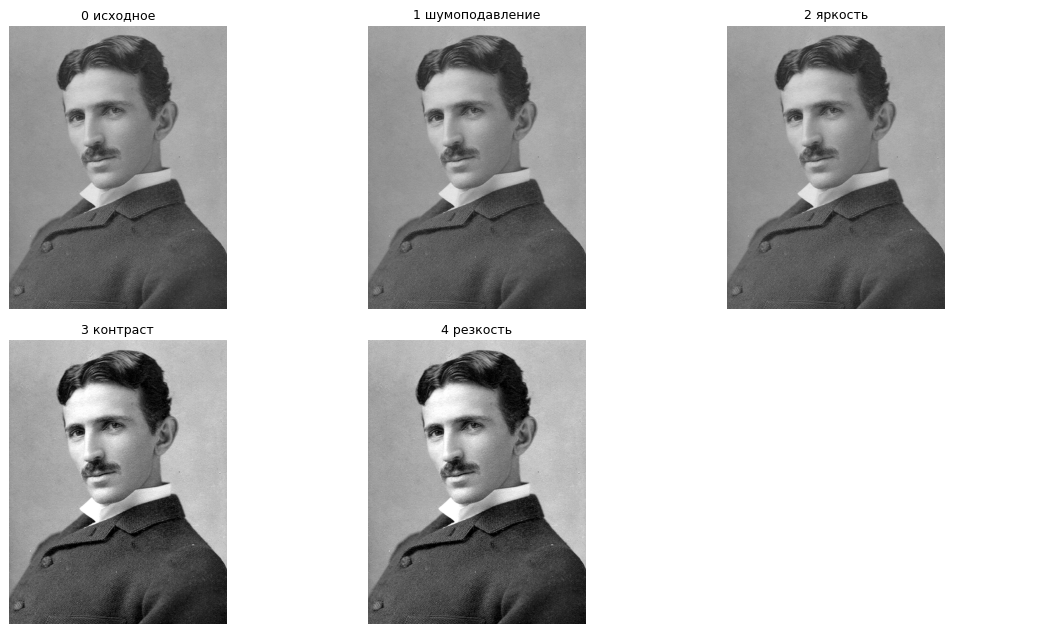

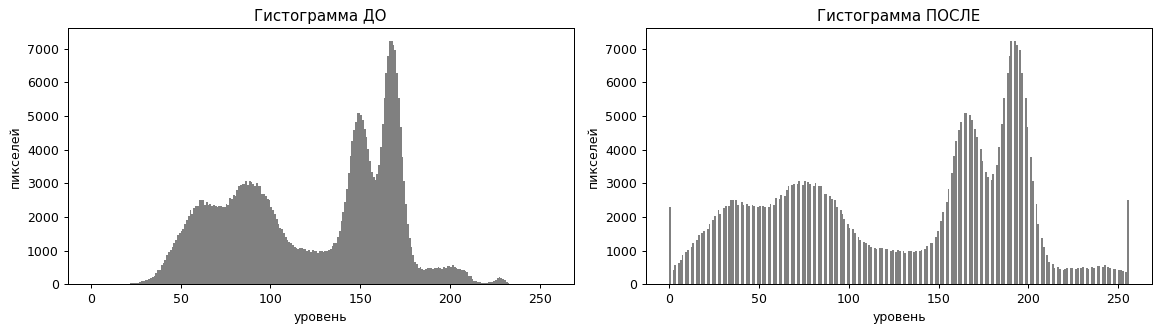

,до,после
яркость,123.34,127.43
контраст (σ),44.34,65.13
дин. диапазон (p1–p99),166.00,245.00
"тёмные, %",0.13,7.27
"светлые, %",0.26,3.20
резкость (Var Lap),67.21,147.22
шум σ,1.84,2.72
энтропия,7.14,7.09
blur ratio,0.09,0.07


In [8]:
result, steps, log = auto_enhance(gray, return_steps=True)
print('Журнал конвейера:', log)
show(list(steps.values()), list(steps.keys()), cols=3, size=4.2, name='pipeline_steps')

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, im, t in zip(ax, [gray, result], ['Гистограмма ДО', 'Гистограмма ПОСЛЕ']):
    a.hist(im.ravel(), bins=256, range=(0, 256), color='gray'); a.set_title(t); a.set_xlabel('уровень'); a.set_ylabel('пикселей')
plt.tight_layout(); save_fig('histograms'); plt.show()

before, _ = diagnose(gray); after, _ = diagnose(result)
display(pd.DataFrame({'до': before, 'после': after}).round(2))

**Как читать таблицу.** «Резкость (Var Lap)» после обработки может вырасти не только из-за резкости, но и из-за усиленного шума — поэтому смотрим на неё *вместе* с «шум σ» и коэффициентом размытия, а не по отдельности (именно так в первой версии проекта резкость «выросла вдвое»: часть этого роста давал шум, усиленный CLAHE).

## 6. Тестирование и устойчивость
Берём эталонные снимки, **портим их известным способом** и смотрим, насколько результат близок к эталону (PSNR ↑, SSIM ↑). Сравниваем три варианта: испорченный снимок (без обработки), **исходный конвейер** (baseline) и **адаптивный конвейер**. Дефекты: тёмное (γ=2.2), засвеченное (γ=0.45 + смещение), низкий контраст (×0.45), размытие (σ=2.5), гауссов шум (σ=20), комбинация (тёмное + размытие + шум). Контроль — **неиспорченное** фото: хороший конвейер не должен его менять (исключение — снимок, малоконтрастный по природе: `chelsea` имеет диапазон ≈160 из 255 и получает растяжение, поэтому в контроле он меняется).

*Оговорка:* дефекты синтетические и «идеальные» (например, низкий контраст — это линейное сжатие, поэтому линейное растяжение его почти точно обращает). Реальные дефекты сложнее, поэтому для настоящего снимка (раздел 5) опираемся на метрики без эталона и визуальную оценку.

In [9]:
# ---------- деградации ----------
def deg_dark(x):  return (255 * (x / 255.0) ** 2.2).astype(np.uint8)
def deg_bright(x): return np.clip(255 * (x / 255.0) ** 0.45 + 25, 0, 255).astype(np.uint8)
def deg_lowc(x):  return np.clip(0.45 * (x.astype(np.float32) - 128) + 128, 0, 255).astype(np.uint8)
def deg_blur(x):  return cv2.GaussianBlur(x, (0, 0), 2.5)
def add_noise(x, sigma=20, seed=1):
    return np.clip(x.astype(np.float32) + np.random.default_rng(seed).normal(0, sigma, x.shape), 0, 255).astype(np.uint8)
def deg_noise(x): return add_noise(x, 20)
def add_clipping(x, offset): return np.clip(x.astype(np.int16) + offset, 0, 255).astype(np.uint8)   # засветка с потерей информации
def deg_combo(x): return deg_noise(cv2.GaussianBlur(deg_dark(x), (0, 0), 1.5))
DEGS = {'тёмное': deg_dark, 'засвеченное': deg_bright, 'низкий контраст': deg_lowc,
        'размытое': deg_blur, 'шум σ=20': deg_noise, 'комбинация': deg_combo}

In [10]:
REFS = {n: cv2.cvtColor(cv2.resize(getattr(sd, n)(), None, fx=0.8, fy=0.8), cv2.COLOR_RGB2BGR) for n in ['astronaut', 'coffee', 'chelsea']}
NIGHT = cv2.cvtColor(cv2.resize(sd.rocket(), None, fx=0.8, fy=0.8), cv2.COLOR_RGB2BGR)   # ночная сцена — «трудный» случай

def evaluate(ref, d):
    t0 = time.perf_counter(); a = auto_enhance(d); t_auto = time.perf_counter() - t0
    b = baseline_enhance(d)
    return dict(psnr_deg=psnr(ref, d), psnr_base=psnr(ref, b), psnr_auto=psnr(ref, a),
                ssim_deg=ssim(ref, d), ssim_base=ssim(ref, b), ssim_auto=ssim(ref, a), время_с=t_auto)

rows = []
for rn, ref in REFS.items():
    for case, d in {'контроль (без дефекта)': ref, **{k: f(ref) for k, f in DEGS.items()}}.items():
        rows.append(dict(снимок=rn, случай=case, **evaluate(ref, d)))
bench = pd.DataFrame(rows)
bench.loc[bench['случай'].str.startswith('контроль'), ['psnr_deg', 'ssim_deg']] = np.nan   # PSNR=∞ для неизменённого — не показываем
summary = bench.groupby('случай').mean(numeric_only=True).round(3)
order = ['контроль (без дефекта)', 'тёмное', 'засвеченное', 'низкий контраст', 'размытое', 'шум σ=20', 'комбинация']
display(summary.loc[order])
print('Средняя скорость адаптивного конвейера: %.0f мс на снимок (≈%dx%d пикс.)' % (1000 * bench['время_с'].mean(), *list(REFS.values())[0].shape[1::-1]))

,psnr_deg,psnr_base,psnr_auto,ssim_deg,ssim_base,ssim_auto,время_с
случай,,,,,,,
контроль (без дефекта),NaN,20.491,39.523,NaN,0.821,0.973,0.018
тёмное,13.436,16.596,19.576,0.705,0.694,0.878,0.018
засвеченное,10.385,12.539,17.078,0.761,0.758,0.909,0.018
низкий контраст,16.991,17.899,19.932,0.780,0.834,0.937,0.020
размытое,25.861,20.040,23.230,0.753,0.720,0.792,0.019
шум σ=20,22.506,17.924,23.464,0.522,0.497,0.766,0.438
комбинация,12.940,15.748,18.149,0.313,0.408,0.556,0.435


Средняя скорость адаптивного конвейера: 138 мс на снимок (≈410x410 пикс.)


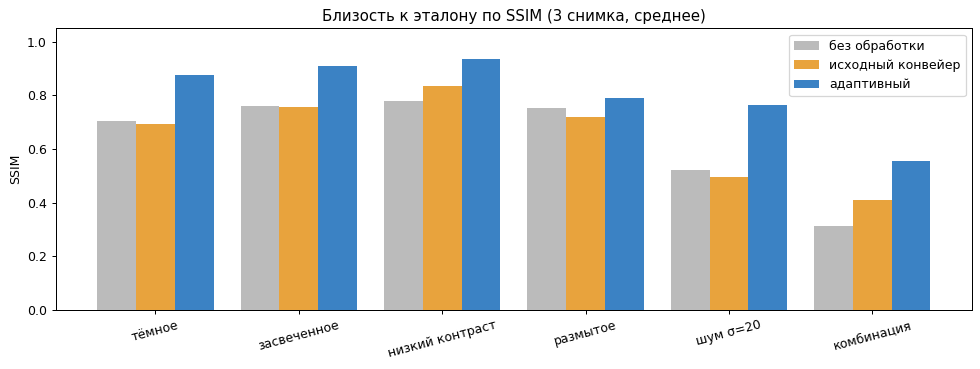

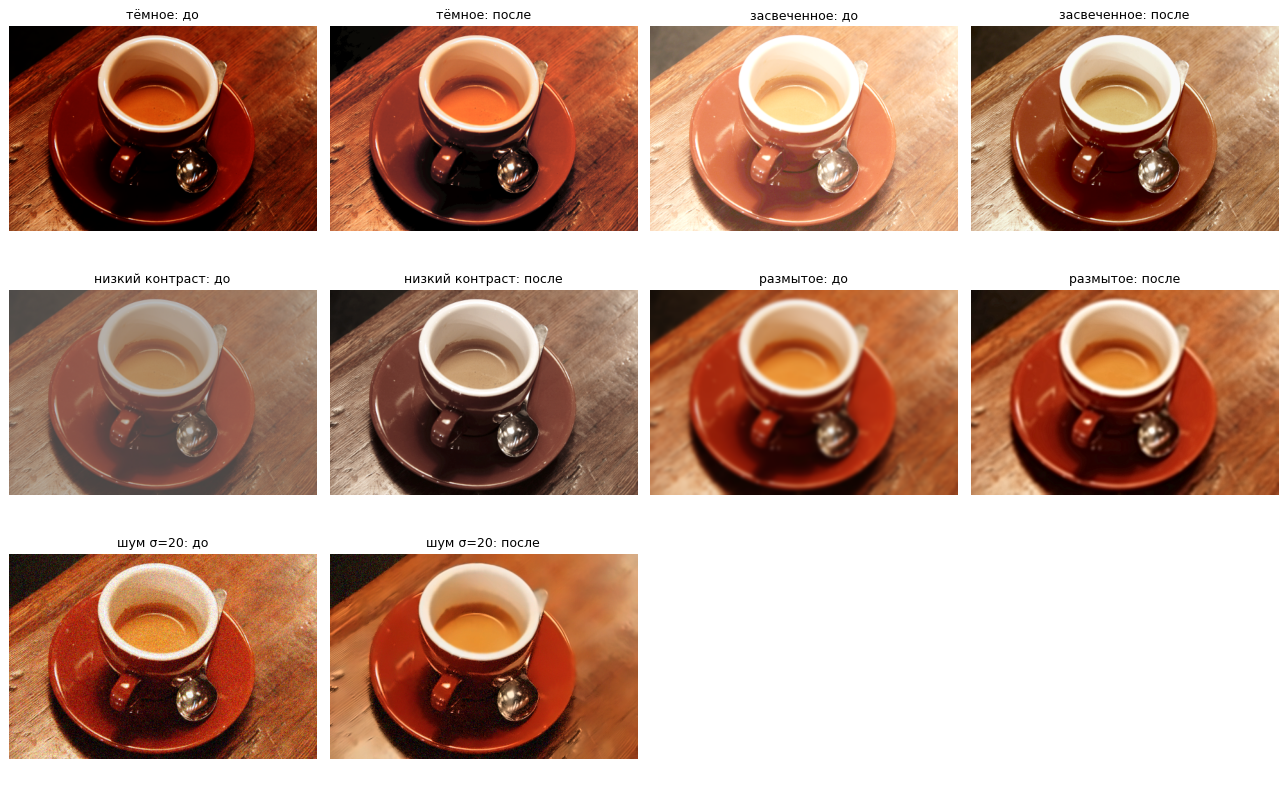

In [11]:
# Сравнение: SSIM по случаям (больше = ближе к эталону)
cases = order[1:]
x = np.arange(len(cases)); w = 0.27
fig, ax = plt.subplots(figsize=(11, 4.2))
for i, (col, lab, c) in enumerate([('ssim_deg', 'без обработки', '#bbb'), ('ssim_base', 'исходный конвейер', '#e8a33d'), ('ssim_auto', 'адаптивный', '#3b82c4')]):
    ax.bar(x + (i - 1) * w, summary.loc[cases, col], w, label=lab, color=c)
ax.set_xticks(x); ax.set_xticklabels(cases, rotation=15); ax.set_ylabel('SSIM'); ax.set_ylim(0, 1.05)
ax.set_title('Близость к эталону по SSIM (3 снимка, среднее)'); ax.legend(); plt.tight_layout(); save_fig('benchmark_ssim'); plt.show()

# Примеры «до / после» для одного снимка
ref = REFS['coffee']
ex, ttl = [], []
for case in ['тёмное', 'засвеченное', 'низкий контраст', 'размытое', 'шум σ=20']:
    d = DEGS[case](ref); ex += [d, auto_enhance(d)]; ttl += [f'{case}: до', f'{case}: после']
show(ex, ttl, cols=4, size=3.6, name='examples_before_after')

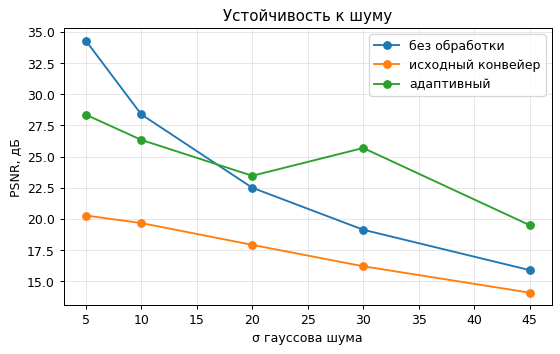

,смещение яркости,"выбитых пикселей, %",SSIM без обработки,SSIM адаптивный
0,0,0.4,1.000,0.973
1,40,6.9,0.879,0.861
2,80,23.0,0.786,0.889
3,120,41.0,0.675,0.795
4,160,60.0,0.526,0.659


In [12]:
# Устойчивость к шуму: сила шума растёт, смотрим PSNR (чем выше, тем лучше)
sigmas = [5, 10, 20, 30, 45]
curve = {'без обработки': [], 'исходный конвейер': [], 'адаптивный': []}
for s in sigmas:
    r = [[psnr(ref_, add_noise(ref_, s)), psnr(ref_, baseline_enhance(add_noise(ref_, s))), psnr(ref_, auto_enhance(add_noise(ref_, s)))] for ref_ in REFS.values()]
    for k, v in zip(curve, np.mean(r, axis=0)): curve[k].append(v)
plt.figure(figsize=(7, 4))
for k, v in curve.items(): plt.plot(sigmas, v, 'o-', label=k)
plt.xlabel('σ гауссова шума'); plt.ylabel('PSNR, дБ'); plt.title('Устойчивость к шуму'); plt.grid(alpha=.3); plt.legend()
save_fig('noise_curve'); plt.show()

# Засветка: чем больше пикселей «выбито» в 255, тем меньше информации можно вернуть
rows = []
for off in [0, 40, 80, 120, 160]:
    clipped = np.mean([(add_clipping(r, off) >= 250).mean() * 100 for r in REFS.values()])
    rows.append({'смещение яркости': off, 'выбитых пикселей, %': round(clipped, 1),
                 'SSIM без обработки': round(np.mean([ssim(r, add_clipping(r, off)) for r in REFS.values()]), 3),
                 'SSIM адаптивный':    round(np.mean([ssim(r, auto_enhance(add_clipping(r, off))) for r in REFS.values()]), 3)})
display(pd.DataFrame(rows))

Журнал для ночной сцены: {'проблемы': ['тёмное'], 'gamma': 0.63}


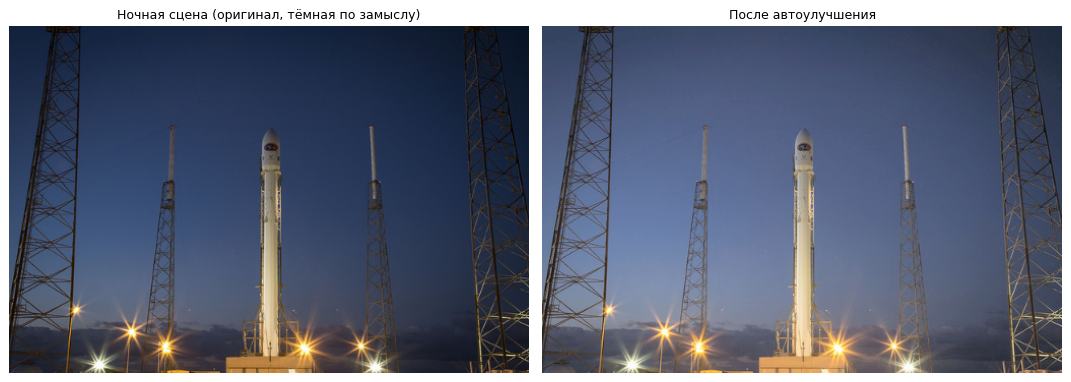

,случай,лиц до,лиц после
0,эталон,1,1
1,тёмное,2,1
2,засвеченное,1,1
3,низкий контраст,1,1
4,размытое,1,1
5,шум σ=20,1,1
6,комбинация,1,1


In [13]:
# Нестандартный случай: ночная сцена. Тёмная по замыслу фотографа, но диагностика видит «тёмное фото».
res_night, _, log_night = auto_enhance(NIGHT, return_steps=True)
print('Журнал для ночной сцены:', log_night)
show([NIGHT, res_night], ['Ночная сцена (оригинал, тёмная по замыслу)', 'После автоулучшения'], size=6, name='night_failure')

# Практическая проверка полезности: находит ли детектор лиц (Haar) лицо на испорченных снимках до/после обработки
face = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
count = lambda im: len(face.detectMultiScale(to_L(im), 1.1, 5, minSize=(40, 40)))
ref = REFS['astronaut']; rows = [{'случай': 'эталон', 'лиц до': count(ref), 'лиц после': count(auto_enhance(ref))}]
for case, f in DEGS.items():
    d = f(ref); rows.append({'случай': case, 'лиц до': count(d), 'лиц после': count(auto_enhance(d))})
display(pd.DataFrame(rows))

## 7. Колоризация чёрно-белых фото
**Метод.** Предобученная свёрточная сеть Zhang et al. (*Colorful Image Colorization*, ECCV 2016): по яркости L она предсказывает распределение цветов (313 кластеров в пространстве ab) для каждого пикселя. Запускается через `cv2.dnn`, дообучать не нужно.

**Почему не классика.** Цвет по яркости определён неоднозначно (серая рубашка может быть любого цвета), поэтому нужны статистические «знания о мире», которые даёт только обученная модель. Это единственное место проекта, где используется нейросеть; всё остальное — классическое CV.

**Проблемы, которые были видны в первой версии** (цвет «протекал» с кожи на белый воротник, на одежде появлялись цветные пятна, фон получал оранжевый оттенок), и **что с ними сделано:**
1. Сети подавали уже «прожжённый» CLAHE и резкостью кадр, а она обучалась на естественных. → теперь сеть видит исходный (слегка очищенный от шума) кадр, а улучшенная яркость подставляется *после*.
2. Сеть работает на 224×224 и выдаёт цвет 56×56, который просто растягивали. → цвет подтягивается к границам яркости **управляемым фильтром** (guided filter), а у почти белых и почти чёрных областей насыщенность гасится.
3. Один проход даёт случайные цветовые пятна. → **усреднение по двум проходам** (кадр и его зеркальное отражение, test-time augmentation).
4. Выход сети слегка бледный → регулируемый множитель насыщенности.

Каждое улучшение проверяется отдельно (варианты A–D), а лучший вариант выбирается **по измеренной ошибке цвета**, а не на глаз.

In [14]:
def guided_filter(guide, src, r, eps):
    """Управляемый фильтр (He et al., 2010): сглаживает src, но сохраняет границы guide.
    q = mean(a)·I + mean(b), a = cov(I,p)/(var(I)+eps), b = mean(p) − a·mean(I)."""
    k = (2 * r + 1, 2 * r + 1); box = lambda x: cv2.boxFilter(x, -1, k, normalize=True)
    I, p = guide.astype(np.float32), src.astype(np.float32)
    mI, mp = box(I), box(p)
    a = (box(I * p) - mI * mp) / (box(I * I) - mI * mI + eps)
    b = mp - a * mI
    return box(a) * I + box(b)

def refine_ab(ab, L, r=None, eps=1e-3):
    """Подтягиваем цветовые каналы к границам яркости: убирает «протекание» цвета через контуры."""
    h, w = L.shape
    r = r or max(4, min(h, w) // 60)
    g = (L / 100.0).astype(np.float32)
    return np.dstack([guided_filter(g, ab[:, :, c], r, eps) for c in range(2)])

def attenuate_extremes(ab, L, hi=85.0, lo=12.0, k=0.7):
    """Почти белые и почти чёрные области нейтральны по цвету: гасим там насыщенность (убирает розовый ореол на белом)."""
    w = np.clip((L - hi) / 10.0, 0, 1) + np.clip((lo - L) / lo, 0, 1)
    return ab * (1 - k * np.clip(w, 0, 1))[:, :, None]

def colorfulness(rgb_u8):
    """Hasler & Süsstrunk (2003): метрика «красочности» изображения."""
    R, G, B = [rgb_u8[:, :, i].astype(np.float32) for i in range(3)]
    rg, yb = R - G, 0.5 * (R + G) - B
    return float(np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean()))

In [15]:
# ---------- колоризация (сеть Zhang et al., ECCV 2016, через cv2.dnn) ----------
MODEL_FILES = {
    'colorization_deploy_v2.prototxt': ['https://raw.githubusercontent.com/richzhang/colorization/caffe/colorization/models/colorization_deploy_v2.prototxt'],
    'pts_in_hull.npy': ['https://github.com/richzhang/colorization/raw/caffe/colorization/resources/pts_in_hull.npy'],
    'colorization_release_v2.caffemodel': [
        'https://huggingface.co/spaces/BilalSardar/Black-N-White-To-Color/resolve/main/colorization_release_v2.caffemodel',
        'https://people.eecs.berkeley.edu/~rich.zhang/projects/2016_colorization/files/demo_v2/colorization_release_v2.caffemodel'],
}
MIN_SIZE = {'colorization_deploy_v2.prototxt': 5_000, 'pts_in_hull.npy': 4_000, 'colorization_release_v2.caffemodel': 100_000_000}

def download_models(folder='models'):
    """Скачивает файлы модели один раз (повторно не качает, если размер верный)."""
    os.makedirs(folder, exist_ok=True)
    for name, urls in MODEL_FILES.items():
        path = os.path.join(folder, name)
        if os.path.exists(path) and os.path.getsize(path) >= MIN_SIZE[name]: continue
        for url in urls:
            try:
                urllib.request.urlretrieve(url, path)
                if os.path.getsize(path) >= MIN_SIZE[name]: break
            except Exception as e:
                print('не удалось скачать', url, '->', type(e).__name__)
        else:
            raise RuntimeError(f'Не скачался {name}. Проверьте интернет или скачайте файл вручную в папку {folder}/')
    return folder

def load_colorizer(folder='models'):
    folder = download_models(folder)
    net = cv2.dnn.readNet(os.path.join(folder, 'colorization_deploy_v2.prototxt'),
                          os.path.join(folder, 'colorization_release_v2.caffemodel'))
    pts = np.load(os.path.join(folder, 'pts_in_hull.npy')).transpose().reshape(2, 313, 1, 1).astype(np.float32)
    net.getLayer(net.getLayerId('class8_ab')).blobs = [pts]                                    # 313 центров кластеров ab
    net.getLayer(net.getLayerId('conv8_313_rh')).blobs = [np.full([1, 313], 2.606, np.float32)]  # масштаб (из репозитория авторов)
    return net

def gray_to_L(gray_u8):
    """Яркость L (0..100) серого изображения — в том же виде, в каком её ждёт сеть."""
    rgb = cv2.cvtColor(gray_u8, cv2.COLOR_GRAY2RGB).astype(np.float32) / 255.0
    return cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)[:, :, 0]

def predict_ab(net, gray_u8, tta=True):
    """Предсказание цветовых каналов ab. Вход сети — 224×224, выход — 56×56 (потом растягиваем до размера кадра).
    tta=True: усредняем предсказания для кадра и его зеркального отражения (меньше случайных цветовых пятен)."""
    h, w = gray_u8.shape
    L = gray_to_L(gray_u8)
    inp = cv2.resize(L, (224, 224), interpolation=cv2.INTER_AREA) - 50          # центрирование яркости, как при обучении
    run = lambda x: (net.setInput(cv2.dnn.blobFromImage(np.ascontiguousarray(x))), net.forward()[0].transpose(1, 2, 0))[1]
    ab = run(inp)
    if tta: ab = 0.5 * (ab + run(inp[:, ::-1])[:, ::-1])
    return cv2.resize(ab, (w, h), interpolation=cv2.INTER_CUBIC)

def colorize(net, gray_L_source, gray_net_input, tta=True, refine=False, neutral=False, sat=1.0):
    """Цвет от сети (по gray_net_input) + яркость из gray_L_source (улучшенный кадр) -> RGB uint8."""
    ab = predict_ab(net, gray_net_input, tta)
    L = gray_to_L(gray_L_source)
    if refine:  ab = refine_ab(ab, L)
    if neutral: ab = attenuate_extremes(ab, L)
    ab = ab * sat
    rgb = cv2.cvtColor(np.dstack([L, ab]).astype(np.float32), cv2.COLOR_LAB2RGB)
    return (np.clip(rgb, 0, 1) * 255).astype(np.uint8)

def delta_ab(rgb_pred_u8, rgb_true_u8):
    """Средняя ошибка цвета (евклидово расстояние в ab, при равной яркости) — «насколько цвет далёк от настоящего»."""
    f = lambda x: cv2.cvtColor(x.astype(np.float32) / 255.0, cv2.COLOR_RGB2LAB)[:, :, 1:]
    return float(np.sqrt(((f(rgb_pred_u8) - f(rgb_true_u8)) ** 2).sum(2)).mean())

In [16]:
# Загрузка модели (скачивается один раз, ~123 МБ)
try:
    net = load_colorizer()
    print('Модель загружена')
except Exception as e:
    net = None
    print('Колоризация недоступна:', e)

Модель загружена


In [17]:
# Варианты колоризации: каждый следующий добавляет одно улучшение
VARIANTS = {
    'A. как в проекте (CLAHE → сеть, 1 проход)': dict(net_in='baseline', tta=False, refine=False, neutral=False),
    'B. сеть видит исходный кадр':               dict(net_in='clean',    tta=False, refine=False, neutral=False),
    'C. B + два прохода (TTA)':                  dict(net_in='clean',    tta=True,  refine=False, neutral=False),
    'D. C + управляемый фильтр + нейтр. белого': dict(net_in='clean',    tta=True,  refine=True,  neutral=True),
}

def run_variant(net, g, cfg, sat=1.0, l_mode='enhanced'):
    """g — серый кадр uint8. l_mode: 'enhanced' — яркость из auto_enhance; 'gray' — исходная (для честного сравнения цвета)."""
    base = baseline_enhance(g)
    s = estimate_noise(g)
    clean = denoise(g, s) if s > DEFAULT_THR['noise'] else g
    net_in = base if cfg['net_in'] == 'baseline' else clean
    if cfg['net_in'] == 'baseline': L_src = base
    else:                           L_src = auto_enhance(g) if l_mode == 'enhanced' else g
    return colorize(net, L_src, net_in, cfg['tta'], cfg['refine'], cfg['neutral'], sat)

In [18]:
if net is not None:
    # Количественное сравнение: цветные эталоны -> в серый -> колоризация -> сравниваем с настоящими цветами
    COLOR_REFS = {**REFS, 'rocket': NIGHT}
    rows = []
    for rn, ref_bgr in COLOR_REFS.items():
        ref_rgb = cv2.cvtColor(ref_bgr, cv2.COLOR_BGR2RGB); g = cv2.cvtColor(ref_bgr, cv2.COLOR_BGR2GRAY)
        for vn, cfg in VARIANTS.items():
            t0 = time.perf_counter(); out = run_variant(net, g, cfg, l_mode='gray'); dt = time.perf_counter() - t0
            rows.append(dict(снимок=rn, вариант=vn, ошибка_цвета=delta_ab(out, ref_rgb), красочность=colorfulness(out), время_с=dt))
        rows.append(dict(снимок=rn, вариант='эталон (настоящий цвет)', ошибка_цвета=0.0, красочность=colorfulness(ref_rgb), время_с=np.nan))
    cb = pd.DataFrame(rows)
    color_summary = cb.groupby('вариант', sort=False).mean(numeric_only=True).round(2)
    display(color_summary)
    print('ошибка_цвета: среднее расстояние между предсказанным и настоящим цветом в плоскости ab (меньше = лучше).')
    print('Важно: настоящий цвет — лишь один из правдоподобных, поэтому метрика строгая; красочность показывает «живость» картинки.')
    cand = {k: v for k, v in color_summary['ошибка_цвета'].items() if k[0] in 'BCD'}
    BEST = min(cand, key=cand.get)
    print('Лучший по ошибке цвета среди B–D:', BEST)

,ошибка_цвета,красочность,время_с
вариант,,,
"A. как в проекте (CLAHE → сеть, 1 проход)",17.87,51.11,1.08
B. сеть видит исходный кадр,14.91,52.32,0.93
C. B + два прохода (TTA),14.19,51.75,1.85
D. C + управляемый фильтр + нейтр. белого,13.76,50.96,1.77
эталон (настоящий цвет),0.00,56.13,NaN


ошибка_цвета: среднее расстояние между предсказанным и настоящим цветом в плоскости ab (меньше = лучше).
Важно: настоящий цвет — лишь один из правдоподобных, поэтому метрика строгая; красочность показывает «живость» картинки.
Лучший по ошибке цвета среди B–D: D. C + управляемый фильтр + нейтр. белого


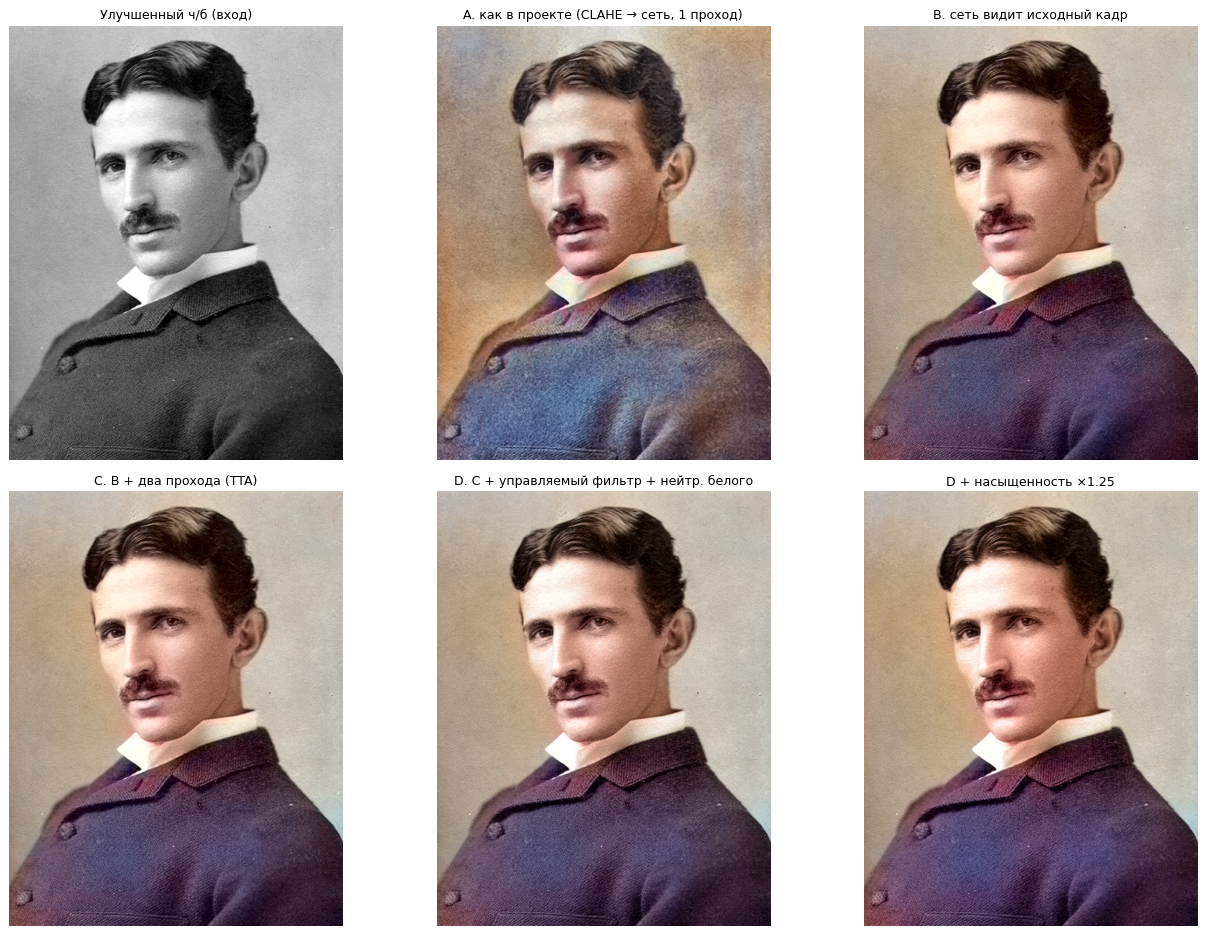

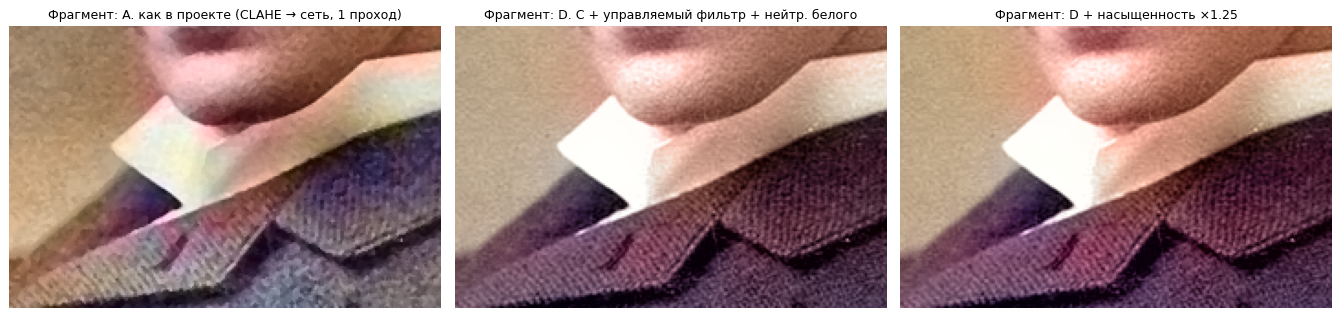

In [19]:
if net is not None:
    g_user = gray if gray.ndim == 2 else cv2.cvtColor(gray, cv2.COLOR_BGR2GRAY)
    outs = {vn: run_variant(net, g_user, cfg) for vn, cfg in VARIANTS.items()}
    outs['D + насыщенность ×1.25'] = run_variant(net, g_user, VARIANTS['D. C + управляемый фильтр + нейтр. белого'], sat=1.25)
    enh = auto_enhance(g_user)
    imgs = [cv2.cvtColor(enh, cv2.COLOR_GRAY2RGB)] + list(outs.values())
    names = ['Улучшенный ч/б (вход)'] + list(outs.keys())
    fig, axs = plt.subplots(2, 3, figsize=(15, 10.5))
    for ax, im, t in zip(axs.ravel(), imgs, names):
        ax.imshow(im); ax.set_title(t, fontsize=10); ax.axis('off')
    plt.tight_layout(); save_fig('colorization_variants'); plt.show()

    # Увеличенный фрагмент (область воротника/подбородка), где раньше был розовый ореол
    h, w = g_user.shape; y0, y1, x0, x1 = int(.50 * h), int(.72 * h), int(.22 * w), int(.66 * w)
    fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
    for ax, key in zip(axs, list(outs.keys())[:1] + list(outs.keys())[3:4] + list(outs.keys())[4:5]):
        ax.imshow(outs[key][y0:y1, x0:x1]); ax.set_title('Фрагмент: ' + key, fontsize=10); ax.axis('off')
    plt.tight_layout(); save_fig('colorization_zoom'); plt.show()

## 8. Итоговая система
`process_photo` объединяет всё: определяет тип снимка, диагностирует, улучшает, а чёрно-белые фото ещё и раскрашивает (лучший вариант колоризации выбирается автоматически по таблице выше). Выводит отчёт и сравнение «до / после».

Тип снимка: чёрно-белый | найденные проблемы: ['низкий контраст']
Применено: {'stretch gain': np.float64(1.48)}


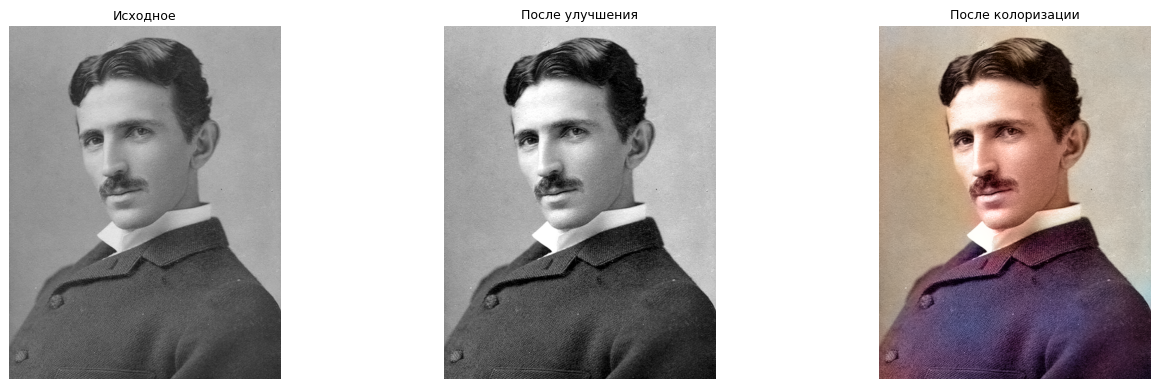

,до,после
яркость,123.34,127.43
контраст (σ),44.34,65.13
дин. диапазон (p1–p99),166.00,245.00
"тёмные, %",0.13,7.27
"светлые, %",0.26,3.20
резкость (Var Lap),67.21,147.22
шум σ,1.84,2.72
энтропия,7.14,7.09
blur ratio,0.09,0.07


In [20]:
def process_photo(image, net=None, sat=1.15, show_result=True, save_as=None, treat_as_bw=None):
    """Полный конвейер: диагностика -> улучшение -> (для ч/б) колоризация.
    treat_as_bw: None — определить автоматически; True — считать снимок чёрно-белым (полезно для подкрашенных сканов, например сепия)."""
    image = limit_size(image)
    bw = is_grayscale(image) if treat_as_bw is None else treat_as_bw
    src = (image if image.ndim == 2 else cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)) if bw else image
    stats_before, issues = diagnose(src)
    enhanced, steps, log = auto_enhance(src, return_steps=True)
    stats_after, _ = diagnose(enhanced)
    final, label = enhanced, 'Улучшенное ч/б' if bw else 'Улучшенное фото'
    if bw and net is not None:
        cfg = VARIANTS[BEST] if 'BEST' in globals() else VARIANTS['D. C + управляемый фильтр + нейтр. белого']
        rgb = run_variant(net, src, cfg, sat=sat); final = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR); label = 'Улучшение + колоризация'
    report = pd.DataFrame({'до': stats_before, 'после': stats_after}).round(2)
    if show_result:
        print('Тип снимка:', 'чёрно-белый' if bw else 'цветной', '| найденные проблемы:', log['проблемы'])
        print('Применено:', {k: v for k, v in log.items() if k != 'проблемы'} or 'ничего (снимок в порядке)')
        show([src, enhanced] + ([final] if final is not enhanced else []), ['Исходное', 'После улучшения'] + (['После колоризации'] if final is not enhanced else []), size=5.2, name=save_as)
        display(report)
    if save_as: cv2.imwrite(f'results/{save_as}.jpg', final)
    return final, report

# если ваш снимок — чёрно-белый скан с цветным оттенком (сепия) и автоопределение не сработало: treat_as_bw=True
final, report = process_photo(img, net, save_as='final_result')

Saving images.jpg to images.jpg
Тип снимка: чёрно-белый | найденные проблемы: ['засвеченное']
Применено: {'gamma': 1.96}


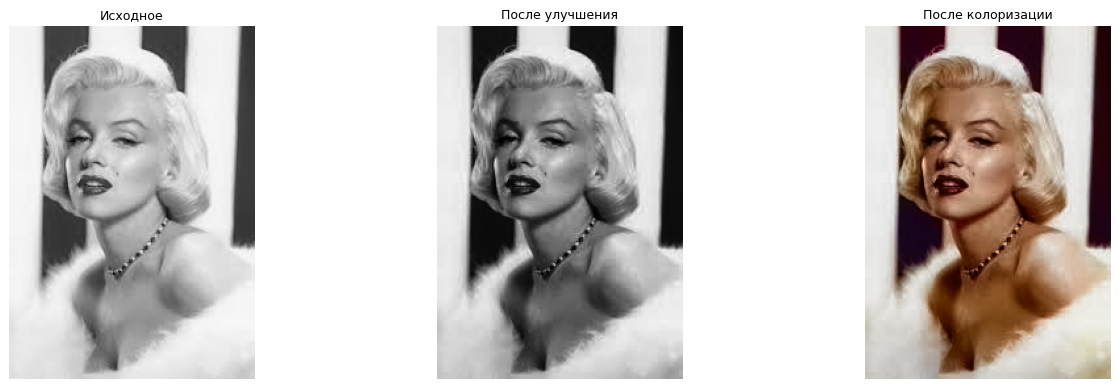

,до,после
яркость,182.64,146.07
контраст (σ),61.15,76.11
дин. диапазон (p1–p99),194.00,228.00
"тёмные, %",0.10,12.61
"светлые, %",35.62,21.20
резкость (Var Lap),172.29,221.52
шум σ,1.04,1.33
энтропия,7.14,6.99
blur ratio,0.13,0.13


In [21]:
# Живая демонстрация: загрузите любую фотографию (в Colab откроется окно выбора файла)
try:
    from google.colab import files
    up = files.upload()
    for fname in up:
        im = cv2.imread(fname)
        if im is not None: process_photo(im, net, save_as='demo_' + os.path.splitext(fname)[0])
except ImportError:
    print('Не Colab: используйте process_photo(cv2.imread("путь.jpg"), net)')

## 9. Выводы

In [22]:
# Автоматическая сводка по числам из этого запуска
def winner(r, m):
    v = {'без обработки': r[f'{m}_deg'], 'исходный конвейер': r[f'{m}_base'], 'адаптивный': r[f'{m}_auto']}
    return max(v, key=v.get)
print('Кто ближе к эталону в каждом случае:')
for k in order[1:]:
    r = summary.loc[k]
    print(f"  {k:16s} SSIM -> {winner(r,'ssim'):18s} | PSNR -> {winner(r,'psnr'):18s} (SSIM: дефект {r.ssim_deg}, исходный {r.ssim_base}, адаптивный {r.ssim_auto})")
ctl = summary.loc['контроль (без дефекта)']
print(f"\nКонтроль (хорошие фото): SSIM исходного конвейера {ctl.ssim_base} против адаптивного {ctl.ssim_auto} (1.0 = фото не тронуто).")
if net is not None:
    print('\nКолоризация, ошибка цвета (меньше = лучше):'); print(color_summary['ошибка_цвета'].to_string())

Кто ближе к эталону в каждом случае:
  тёмное           SSIM -> адаптивный         | PSNR -> адаптивный         (SSIM: дефект 0.705, исходный 0.694, адаптивный 0.878)
  засвеченное      SSIM -> адаптивный         | PSNR -> адаптивный         (SSIM: дефект 0.761, исходный 0.758, адаптивный 0.909)
  низкий контраст  SSIM -> адаптивный         | PSNR -> адаптивный         (SSIM: дефект 0.78, исходный 0.834, адаптивный 0.937)
  размытое         SSIM -> адаптивный         | PSNR -> без обработки      (SSIM: дефект 0.753, исходный 0.72, адаптивный 0.792)
  шум σ=20         SSIM -> адаптивный         | PSNR -> адаптивный         (SSIM: дефект 0.522, исходный 0.497, адаптивный 0.766)
  комбинация       SSIM -> адаптивный         | PSNR -> адаптивный         (SSIM: дефект 0.313, исходный 0.408, адаптивный 0.556)

Контроль (хорошие фото): SSIM исходного конвейера 0.821 против адаптивного 0.973 (1.0 = фото не тронуто).

Колоризация, ошибка цвета (меньше = лучше):
вариант
A. как в проекте (CLAHE →

**Что получилось.** Построена система, которая по измеренным характеристикам снимка (яркость, динамический диапазон, шум по Иммеркеру, размытость по повторному размытию) выбирает шаги и параметры улучшения; хорошее фото она не трогает. Используются в комбинации: гистограммы и пороговая сегментация (диагностика и маски), цветовые пространства LAB, фильтрация (NLM, гауссово размытие, управляемый фильтр), поиск контуров (Canny) с морфологией, гамма-коррекция, CLAHE, нерезкая маска. Для чёрно-белых фото добавлена колоризация нейросетью с классической постобработкой.

**Что показывают тесты** (числа — в сводке выше). Адаптивный конвейер даёт выигрыш над фиксированным исходным конвейером там, где дефект «нужного типа» (тёмное, засвеченное, низкий контраст, шум), потому что исходный применял CLAHE и усиление резкости всегда и одинаково; на хороших неиспорченных снимках адаптивный их не трогает, а исходный портил всегда (SSIM контроля ≈0.82 против ≈0.97 у адаптивного). PSNR на размытых снимках может быть ниже, чем без обработки: нерезкая маска добавляет высокие частоты, а PSNR их штрафует, поэтому для резкости смотрим SSIM и визуальный результат.

**Ограничения и места, где метод ошибается.**
* *Ночные и «тёмные по замыслу» сцены:* автоматика осветляет их (раздел 6, `rocket`) — глобальная гамма не знает замысла снимка.
* *Сильная засветка:* выбитые в 255 пиксели не содержат информации, восстановить её нельзя (таблица по смещению яркости).
* *Размытие:* нерезкая маска усиливает оставшиеся детали, но не возвращает потерянные; для настоящего восстановления нужна деконволюция с известным ядром размытия.
* *Взаимное влияние диагностик:* сильное размытие уменьшает измеряемый динамический диапазон и может быть принято за низкий контраст.
* *Колоризация:* цвета правдоподобные, а не настоящие (сеть не знает, какого цвета была одежда); возможны цветовые пятна на нетипичных сценах. Метрика «ошибка цвета» строга: любой другой правдоподобный цвет считается ошибкой.
* *Метрики:* PSNR/SSIM считаются по синтетическим дефектам; для реальных снимков качество оценивается без эталона и визуально.
* *Перекрытие объектов* для задачи улучшения изображения не применимо и не тестировалось.

**Что можно улучшить.** Локальная (по областям) гамма вместо глобальной; деконволюция Ричардсона–Люси при известном размытии; доверительная оценка параметров по набору реальных фото; современные модели колоризации с пользовательскими подсказками цвета.